In [19]:
!pip install pywavelets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 65.1 MB/s eta 0:00:00


In [20]:
from scipy.io import wavfile
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pywt

In [2]:
path = "/content/signal.wav"

fs, data = wavfile.read(path)

In [5]:
ts = 1/fs
N = len(data)
n = np.arange(N)
t = n*ts

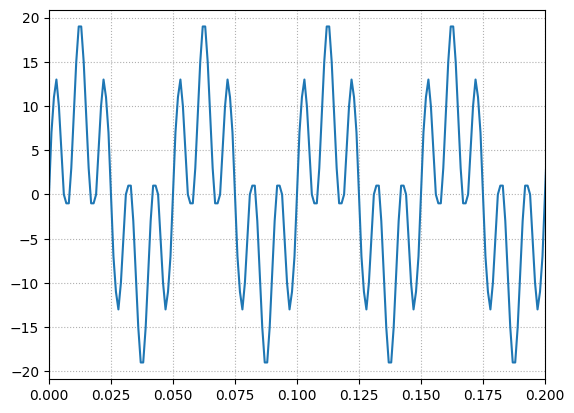

In [9]:
plt.plot(t, data)
plt.xlim(0, 0.2)
plt.grid(ls=":")

# FFT

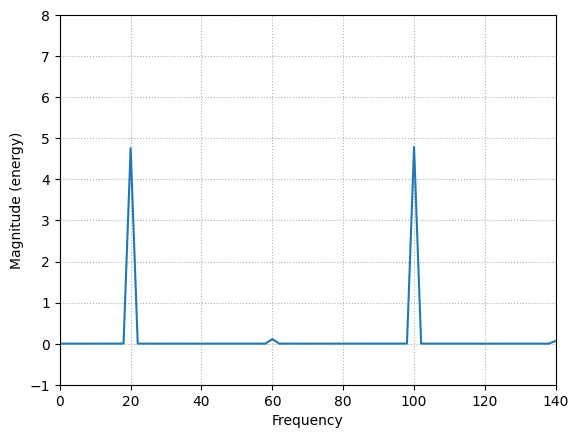

In [16]:
plt.magnitude_spectrum(data, Fs=fs)
plt.xlim(0, 140)
plt.ylim(-1,8)
plt.grid(ls=":")
plt.show()

# Wavelet

In [22]:
coeffs = pywt.wavedec(data,'db6','sym',level=6)
(cA6,cD6,cD5,cD4,cD3,cD2,cD1) = coeffs

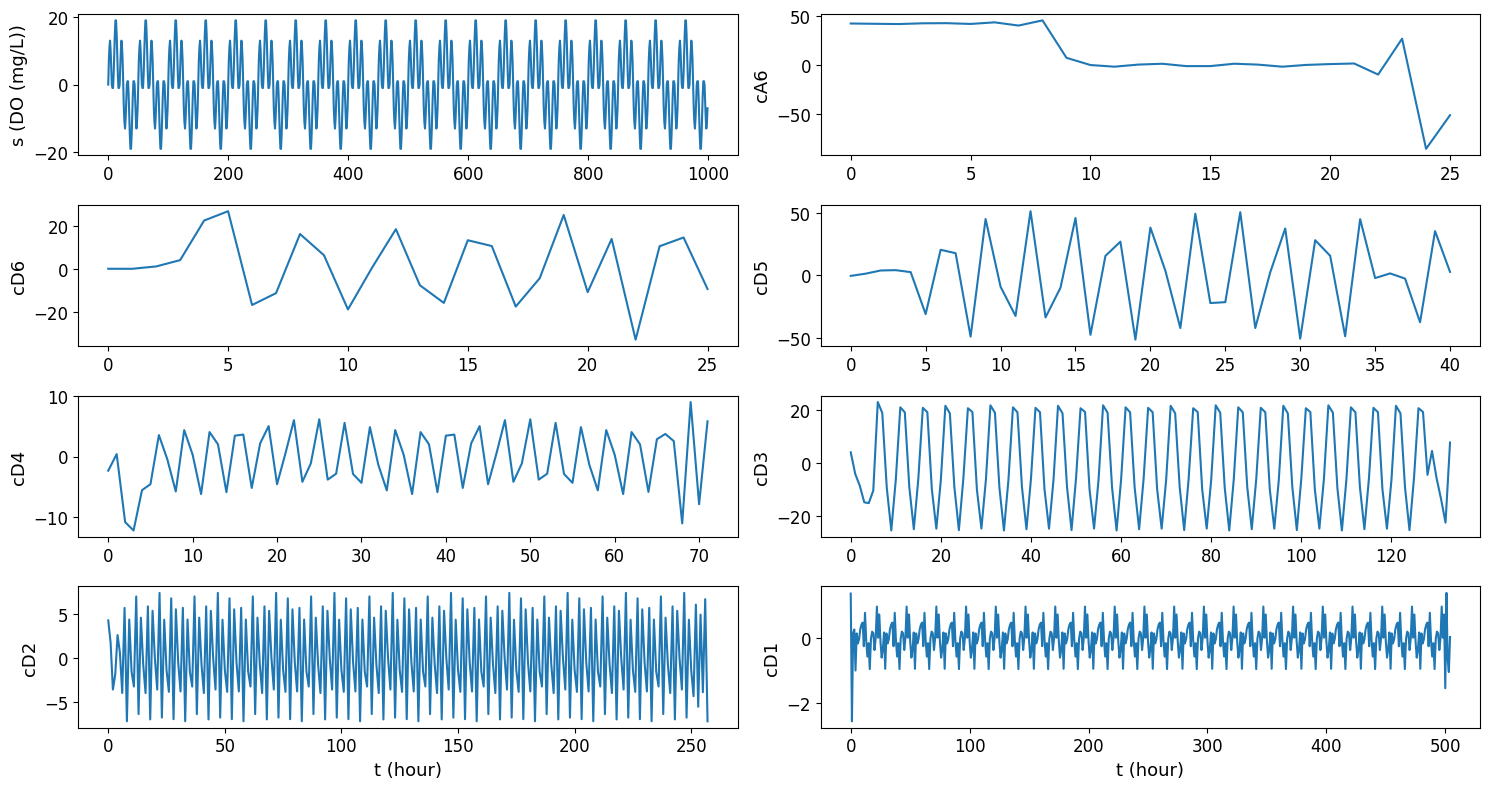

In [47]:
# @title COEFFs
fig,axs = plt.subplots(4,2,figsize=(15,8))
plt.rc('xtick',labelsize=12)
plt.rc('ytick',labelsize=12)
axs[0,0].plot(data)
axs[0,0].set_ylabel('s (DO (mg/L))',fontsize=13)
axs[0,1].plot(cA6)
axs[0,1].set_ylabel('cA6',fontsize=13)
axs[1,0].plot(cD6)
axs[1,0].set_ylabel('cD6',fontsize=13)
axs[1,1].plot(cD5)
axs[1,1].set_ylabel('cD5',fontsize=13)
axs[2,0].plot(cD4)
axs[2,0].set_ylabel('cD4',fontsize=13)
axs[2,1].plot(cD3)
axs[2,1].set_ylabel('cD3',fontsize=13)
axs[3,0].plot(cD2)
axs[3,0].set_ylabel('cD2',fontsize=13)
axs[3,0].set_xlabel('t (hour)',fontsize=13)
axs[3,1].plot(cD1)
axs[3,1].set_ylabel('cD1',fontsize=13)
axs[3,1].set_xlabel('t (hour)',fontsize=13)
plt.tight_layout()
plt.show()

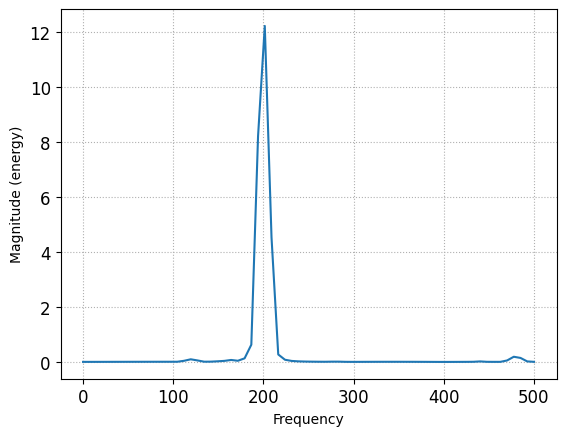

In [54]:
# @title FFT de la señal cD3
# Analizamos cD3
#
plt.magnitude_spectrum(cD3, Fs=fs)
#plt.xlim(0, 140)
#plt.ylim(-1,8)
plt.grid(ls=":")
plt.show()

In [31]:
cA06 = np.zeros(len(cA6))
cD06 = np.zeros(len(cD6))
cD05 = np.zeros(len(cD5))
cD04 = np.zeros(len(cD4))
cD03 = np.zeros(len(cD3))
cD02 = np.zeros(len(cD2))
cD01 = np.zeros(len(cD1))

A6 = pywt.waverec((cA6,cD06,cD05,cD04,cD03,cD02,cD01),'db6','sym')
D6 = pywt.waverec((cA06,cD6,cD05,cD04,cD03,cD02,cD01),'db6','sym')
D5 = pywt.waverec((cA06,cD06,cD5,cD04,cD03,cD02,cD01),'db6','sym')
D4 = pywt.waverec((cA06,cD06,cD05,cD4,cD03,cD02,cD01),'db6','sym')
D3 = pywt.waverec((cA06,cD06,cD05,cD04,cD3,cD02,cD01),'db6','sym')
D2 = pywt.waverec((cA06,cD06,cD05,cD04,cD03,cD2,cD01),'db6','sym')
D1 = pywt.waverec((cA06,cD06,cD05,cD04,cD03,cD02,cD1),'db6','sym')

In [37]:
A5 = A6 + D6
A4 = A6 + D6 + D5
A3 = A6 + D6 + D5 + D4
A2 = A6 + D6 + D5 + D4 + D3
A1 = A6 + D6 + D5 + D4 + D3 + D2

## Detalle

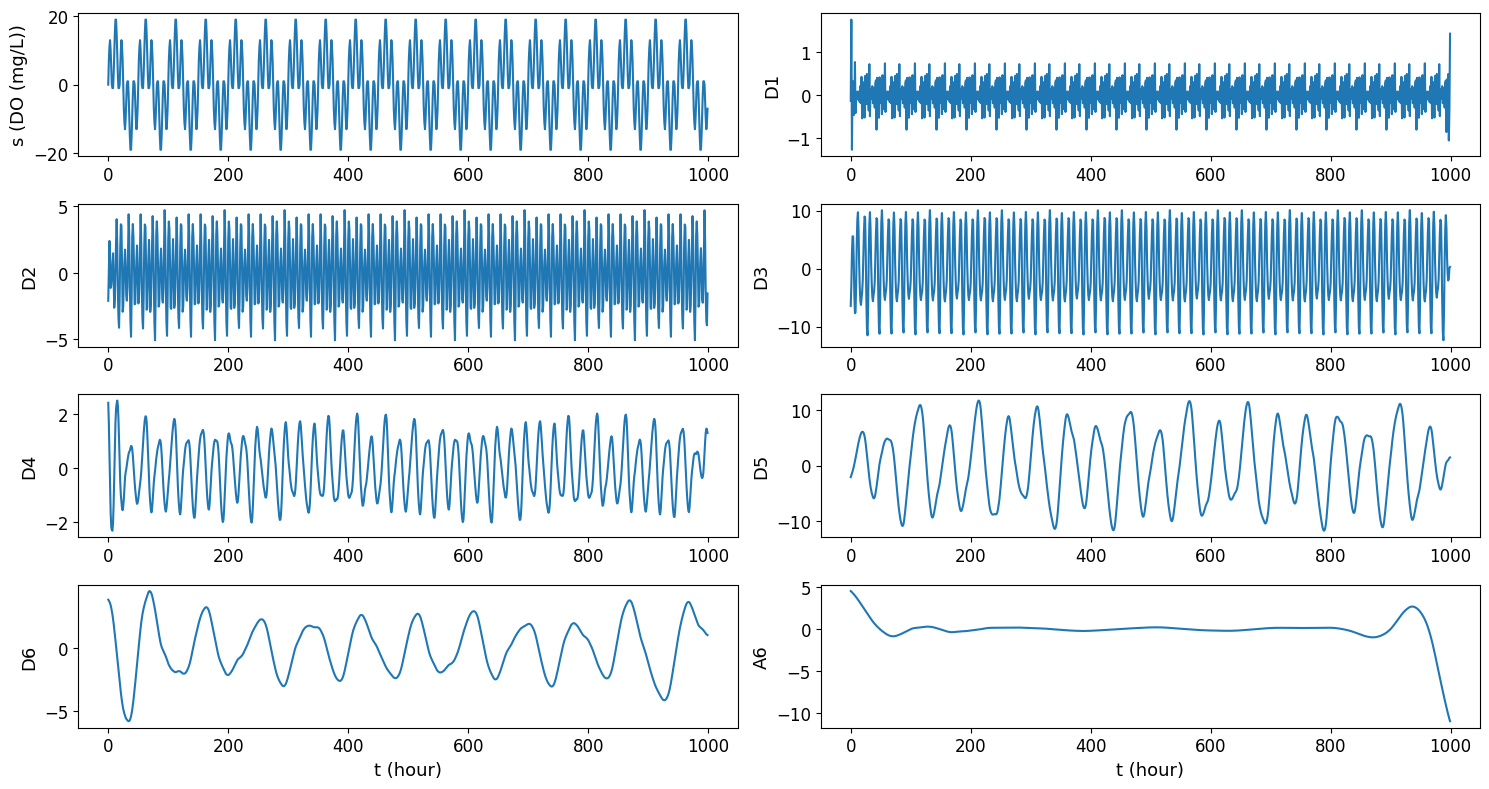

In [50]:
# @title Coeff reconstruidos
fig,axs = plt.subplots(4,2,figsize=(15,8))
plt.rc('xtick',labelsize=12)
plt.rc('ytick',labelsize=12)
axs[0,0].plot(data)
axs[0,0].set_ylabel('s (DO (mg/L))',fontsize=13)
axs[0,1].plot(D1)
axs[0,1].set_ylabel('D1',fontsize=13)
axs[1,0].plot(D2)
axs[1,0].set_ylabel('D2',fontsize=13)
axs[1,1].plot(D3)
axs[1,1].set_ylabel('D3',fontsize=13)
axs[2,0].plot(D4)
axs[2,0].set_ylabel('D4',fontsize=13)
axs[2,1].plot(D5)
axs[2,1].set_ylabel('D5',fontsize=13)
axs[3,0].plot(D6)
axs[3,0].set_ylabel('D6',fontsize=13)
axs[3,0].set_xlabel('t (hour)',fontsize=13)
axs[3,1].plot(A6)
axs[3,1].set_ylabel('A6',fontsize=13)
axs[3,1].set_xlabel('t (hour)',fontsize=13)
plt.tight_layout()
plt.show()

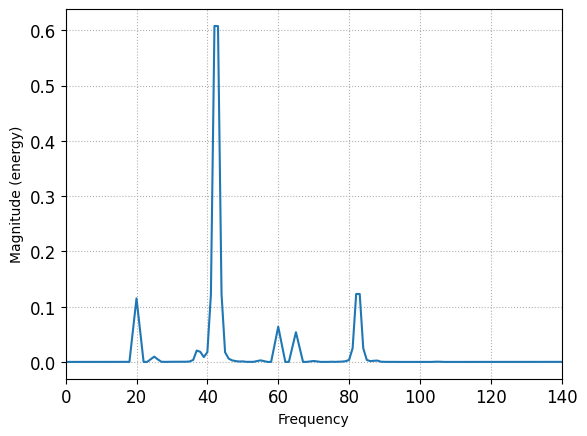

In [52]:
# @title FFT D4
# Analizamos D4
#
plt.magnitude_spectrum(D4, Fs=fs)
plt.xlim(0, 140)
#plt.ylim(-1,8)
plt.grid(ls=":")
plt.show()

## Aproximación

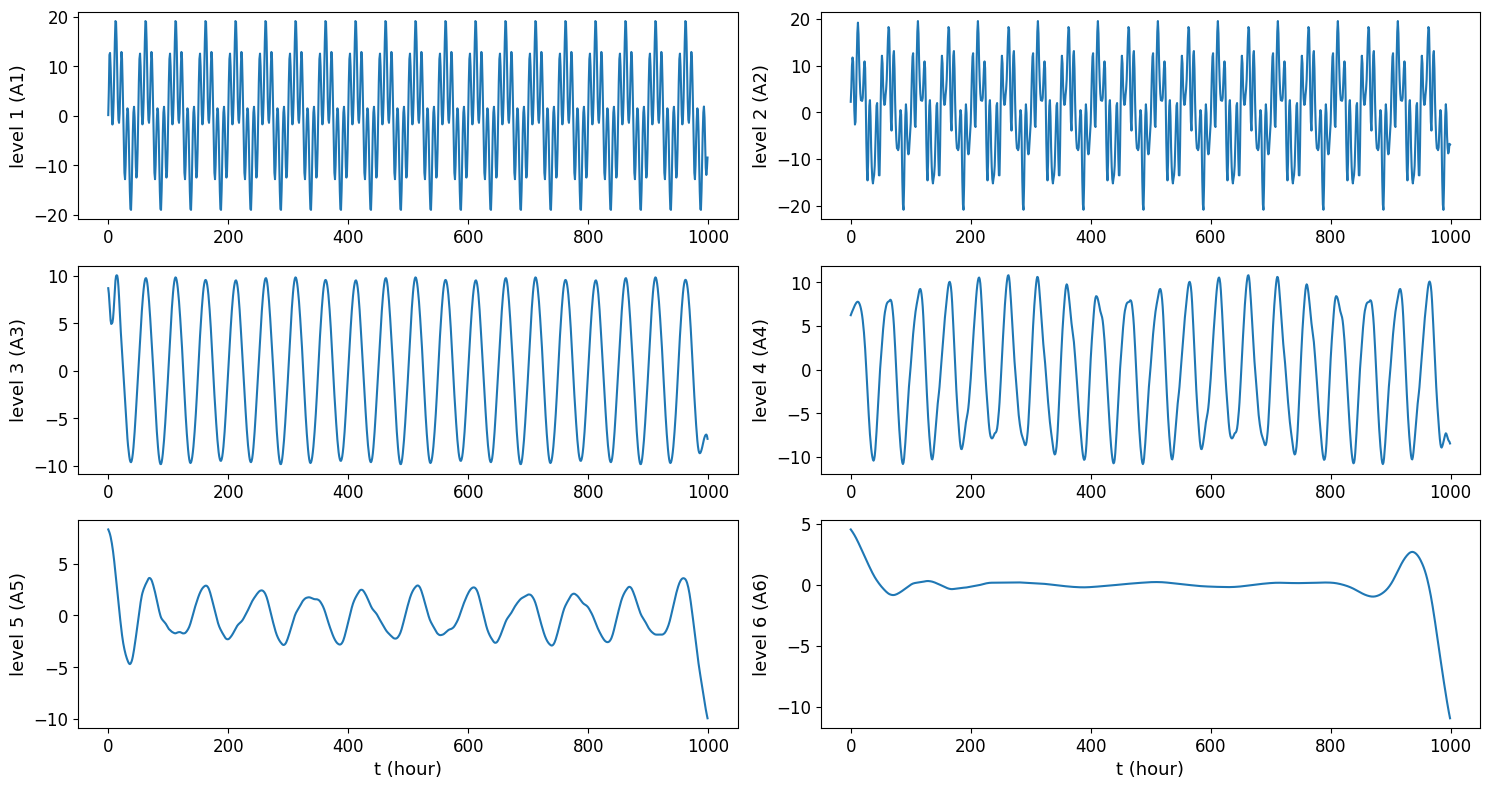

In [44]:
# @title coeff Aproximacion
fig,axs = plt.subplots(3,2,figsize=(15,8))
plt.rc('xtick',labelsize=12)
plt.rc('ytick',labelsize=12)
#axs[0,0].plot(t,x3)
axs[0,0].plot(A1)
axs[0,0].set_ylabel('level 1 (A1)',fontsize=13)
#axs[0,0].legend(('Approimation at level 1 (A1)'),loc='best')

#axs[0,1].plot(t,x3)
axs[0,1].plot(A2)
axs[0,1].set_ylabel('level 2 (A2)',fontsize=13)
#axs[0,1].legend(('Approimation at level 2 (A2)'),loc='best')

#axs[1,0].plot(t,x3)
axs[1,0].plot(A3)
axs[1,0].set_ylabel('level 3 (A3)',fontsize=13)
#axs[1,0].legend(('Approimation at level 3 (A3)'),loc='best')

#axs[1,1].plot(t,x3)
axs[1,1].plot(A4)
axs[1,1].set_ylabel('level 4 (A4)',fontsize=13)
#axs[1,1].legend(('Approimation at level 4 (A4)'),loc='best')

#axs[2,0].plot(t,x3)
axs[2,0].plot(A5)
axs[2,0].set_ylabel('level 5 (A5)',fontsize=13)
#axs[2,0].legend(('Approimation at level 5 (A5)'),loc='best')
axs[2,0].set_xlabel('t (hour)',fontsize=13)

#axs[2,1].plot(t,x3)
axs[2,1].plot(A6)
axs[2,1].set_ylabel('level 6 (A6)',fontsize=13)
#axs[2,1].legend(('Approimation at level 6 (A6)'),loc='best')
axs[2,1].set_xlabel('t (hour)',fontsize=13)
plt.tight_layout()
plt.show()

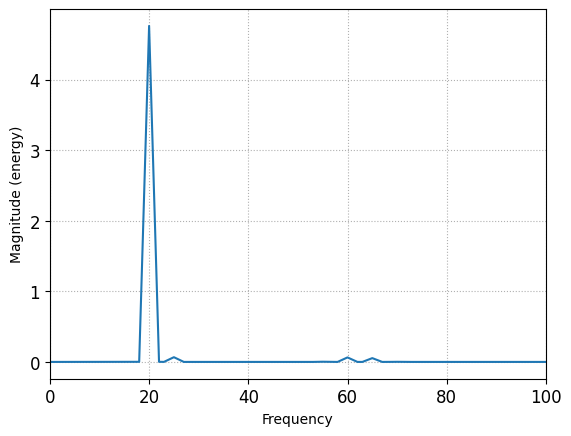

In [46]:
# @title FFt A3
plt.magnitude_spectrum(A3, Fs=fs)
plt.xlim(0, 100)
#plt.ylim(-1,8)
plt.grid(ls=":")
plt.show()